# Mô hình Hồi quy Ridge (Ridge Regression) Dự Báo Giá Cổ Phiếu Apple (AAPL)

- **Mục tiêu:** Dự báo biến động giá ngày kế tiếp (`Delta = NextPrice - Price`), sau đó khôi phục lại giá dự báo $\text{NextPrice} = \text{Price} + \text{Delta}$.
- **Dữ liệu:** Giá cổ phiếu Apple (`Apple_Stock_ready.csv`) gồm 8 đặc trưng cơ sở: `Price`, `Open`, `High`, `Low`, `Volume`, `Return_1`, `High_Low_Range`, `Open_Close_Change`.
- **Phương pháp:** Mô hình tuyến tính có điều chuẩn $L_2$ (Ridge Regression), sử dụng `StandardScaler` và tối ưu hóa siêu tham số $\alpha$ bằng `TimeSeriesSplit(n_splits=5)` và `GridSearchCV`.

## 1. Khai báo các thư viện cần thiết

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

## 2. Đọc dữ liệu từ GitHub
Tải tập dữ liệu đã qua tiền xử lý `Apple_Stock_ready.csv` từ GitHub repository của nhóm và sắp xếp theo thứ tự thời gian tăng dần.

In [2]:
# ============================================================
# 1. ĐỌC DỮ LIỆU TỪ GITHUB
# ============================================================

url = "https://raw.githubusercontent.com/nguyenkhachuy2006-eng/is403/main/Cleaned%20data/Apple_Stock_ready.csv"

df = pd.read_csv(url, parse_dates=["Date"])
df = df.sort_values("Date").reset_index(drop=True)

## 3. Chọn đúng 8 feature cơ sở và tạo biến mục tiêu (Delta)
- 8 đặc trưng: `Price`, `Open`, `High`, `Low`, `Volume`, `Return_1`, `High_Low_Range`, `Open_Close_Change`.
- Biến mục tiêu: $\text{Delta} = \text{NextPrice} - \text{Price}$.

In [3]:
# ============================================================
# 2. CHỌN ĐÚNG 8 FEATURE CƠ SỞ
# ============================================================

feature_cols = [
    "Price",
    "Open",
    "High",
    "Low",
    "Volume",
    "Return_1",
    "High_Low_Range",
    "Open_Close_Change"
]

# Loại bỏ các dòng thiếu dữ liệu
df = df.dropna(
    subset=feature_cols + ["NextPrice"]
).reset_index(drop=True)

# Target: Biến động giá ngày tiếp theo
df["Delta"] = df["NextPrice"] - df["Price"]

print("=== THÔNG TIN DỮ LIỆU ===")
print("Số lượng feature:", len(feature_cols))
print("Feature sử dụng:", feature_cols)
print("Tổng số dòng:", len(df))

=== THÔNG TIN DỮ LIỆU ===
Số lượng feature: 8
Feature sử dụng: ['Price', 'Open', 'High', 'Low', 'Volume', 'Return_1', 'High_Low_Range', 'Open_Close_Change']
Tổng số dòng: 4020


## 4. Chia tập dữ liệu Train / Validation / Test theo thời gian
- Tỷ lệ: 80% cho tập Train toàn bộ (Full Train), 20% cho tập Test.
- Trong tập Full Train, tách tiếp 90% cho `train_fit` và 10% cho `train_val` để kiểm định mô hình trước khi đánh giá trên Test.

In [4]:
# ============================================================
# 3. CHIA TRAIN / VALIDATION / TEST THEO THỜI GIAN
# ============================================================

n = len(df)
i_train = int(n * 0.80)

train = df.iloc[:i_train].copy()
test = df.iloc[i_train:].copy()

i_val = int(len(train) * 0.90)

train_fit = train.iloc[:i_val].copy()
train_val = train.iloc[i_val:].copy()

print("\n=== CHIA DỮ LIỆU ===")
print(f"Train_fit: {len(train_fit)}")
print(f"Train_val: {len(train_val)}")
print(f"Test: {len(test)}")

# Feature và Target (Delta)
X_fit = train_fit[feature_cols]
y_fit = train_fit["Delta"]

X_val = train_val[feature_cols]
y_val = train_val["Delta"]

X_full_train = train[feature_cols]
y_full_train = train["Delta"]

X_test = test[feature_cols]
y_test = test["Delta"]


=== CHIA DỮ LIỆU ===
Train_fit: 2894
Train_val: 322
Test: 804


## 5. Xây dựng mô hình Ridge với TimeSeriesSplit & GridSearchCV
Sử dụng `Pipeline` kết hợp `StandardScaler` và `Ridge` để chuẩn hóa dữ liệu bên trong từng fold của `TimeSeriesSplit(n_splits=5)`, triệt tiêu hoàn toàn rủi ro rò rỉ dữ liệu (data leakage).

### Cơ sở Toán học: Hàm mất mát dạng khai triển của Ridge Regression
$$RSS_{L2} = \sum_{i=1}^n (Y_i - \hat{Y}_i)^2 + \lambda \sum_{j=1}^p B_j^2$$
Khai triển đầy đủ theo phương trình hồi quy tuyến tính $\hat{Y}_i = B_0 + \sum_{j=1}^p B_j X_{ij}$:
$$RSS_{L2} = \sum_{i=1}^n \left( Y_i - B_0 - \sum_{j=1}^p B_j X_{ij} \right)^2 + \lambda \sum_{j=1}^p B_j^2$$

* **Giải thích các ký hiệu:**
  - $RSS_{L2}$: Tổng bình phương sai số có phạt điều chuẩn $L_2$ (Residual Sum of Squares with $L_2$ penalty).
  - $Y_i$: Giá trị biến mục tiêu thực tế của mẫu thứ $i$ (trong đề tài là mức biến động giá $\Delta_i = P_{i+1} - P_i$).
  - $\hat{Y}_i$: Giá trị dự đoán của mô hình cho mẫu thứ $i$.
  - $n$: Số lượng mẫu quan sát trong tập huấn luyện ($n = 3.216$ dòng).
  - $p$: Số lượng đặc trưng đầu vào ($p = 8$ feature cơ sở).
  - $X_{ij}$: Giá trị của đặc trưng thứ $j$ tại quan sát thứ $i$.
  - $B_0$: Hệ số chặn (intercept).
  - $B_j$: Hệ số hồi quy (trọng số) của đặc trưng thứ $j$.
  - $\lambda$: Hệ số điều chuẩn (tuning parameter, tương ứng tham số $\alpha$ trong `scikit-learn`, $\lambda \ge 0$). Khi $\lambda = 0$, mô hình trở về OLS; khi $\lambda$ tăng, các hệ số $B_j$ bị co dần về 0 để kiềm chế phương sai và triệt tiêu ảnh hưởng của đa cộng tuyến.

In [5]:
# ============================================================
# 4. XÂY DỰNG MÔ HÌNH RIDGE
# ============================================================

alphas = np.logspace(-6, 3, 100)
tscv = TimeSeriesSplit(n_splits=5)

pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("ridge", Ridge())
])

# GridSearchCV giúp tránh leakage khi chuẩn hóa trong CV
ridge_model = GridSearchCV(
    estimator=pipeline,
    param_grid={"ridge__alpha": alphas},
    cv=tscv,
    scoring="neg_mean_squared_error",
    n_jobs=-1,
    refit=True
)

## 6. Huấn luyện và dự báo trên tập Validation
Huấn luyện trên `X_fit`, dự báo biến động `Delta` trên `X_val` và cộng lại giá ngày hiện tại để thu được giá dự báo:
$$\text{Pred\_Val} = \text{Price}_t + \Delta_{\text{pred}}$$

In [6]:
# ============================================================
# 5. HUẤN LUYỆN VÀ DỰ BÁO VALIDATION
# ============================================================

ridge_model.fit(X_fit, y_fit)

# Dự báo Delta
delta_pred_val = ridge_model.predict(X_val)

# Khôi phục giá dự báo
pred_val = train_val["Price"].values + delta_pred_val

alpha_val = ridge_model.best_params_["ridge__alpha"]

## 7. Huấn luyện lại trên toàn bộ tập Train và dự báo trên tập Test
Tận dụng toàn bộ 80% dữ liệu huấn luyện (`X_full_train`) để tối ưu hóa siêu tham số $\alpha$ và dự báo cho tập Test:
$$\text{Pred\_Test} = \text{Price}_t + \Delta_{\text{pred}}$$

In [7]:
# ============================================================
# 6. HUẤN LUYỆN LẠI TRÊN TOÀN BỘ TRAIN
# ============================================================

ridge_model.fit(X_full_train, y_full_train)

# Dự báo Delta trên Test
delta_pred_test = ridge_model.predict(X_test)

# Khôi phục giá dự báo
pred_test = test["Price"].values + delta_pred_test

alpha_test = ridge_model.best_params_["ridge__alpha"]

## 8. Đánh giá mô hình (MAE, RMSE, R², Directional Accuracy)
Định nghĩa hàm đánh giá các chỉ số sai số giá tuyệt đối (MAE, RMSE, R²) và độ chính xác dự báo hướng tăng/giảm (Directional Accuracy - DirAcc).

In [8]:
# ============================================================
# 7. ĐÁNH GIÁ MÔ HÌNH
# ============================================================

def metrics(y_true, y_pred, price_t):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)

    # Đánh giá hướng biến động
    dir_true = np.sign(y_true - price_t)
    dir_pred = np.sign(y_pred - price_t)

    diracc = np.mean(dir_true == dir_pred) * 100

    return mae, rmse, r2, diracc


# Validation
val_metrics = metrics(
    train_val["NextPrice"].values,
    pred_val,
    train_val["Price"].values
)

# Test
test_metrics = metrics(
    test["NextPrice"].values,
    pred_test,
    test["Price"].values
)

print("\n=== RIDGE VALIDATION METRICS ===")
print(f"Alpha tối ưu: {alpha_val:.6f}")
print(f"MAE: {val_metrics[0]:.4f}")
print(f"RMSE: {val_metrics[1]:.4f}")
print(f"R²: {val_metrics[2]:.4f}")
print(f"DirAcc: {val_metrics[3]:.2f}%")

print("\n=== RIDGE TEST METRICS ===")
print(f"Alpha tối ưu: {alpha_test:.6f}")
print(f"MAE: {test_metrics[0]:.4f}")
print(f"RMSE: {test_metrics[1]:.4f}")
print(f"R²: {test_metrics[2]:.4f}")
print(f"DirAcc: {test_metrics[3]:.2f}%")


=== RIDGE VALIDATION METRICS ===
Alpha tối ưu: 0.000001
MAE: 2.3224
RMSE: 3.0485
R²: 0.9616
DirAcc: 52.17%

=== RIDGE TEST METRICS ===
Alpha tối ưu: 0.100000
MAE: 2.6547
RMSE: 3.9004
R²: 0.9920
DirAcc: 49.63%


## 9. Xuất kết quả dự báo trên toàn bộ dataset vào thư mục `model_predict`
- Dự báo biến động giá trên toàn bộ tập dữ liệu (4,020 dòng) bằng mô hình Ridge đã huấn luyện.
- Khôi phục giá dự báo `price_pred` = $\text{Price}_t + \Delta_{\text{pred}}$.
- Lưu **duy nhất 1 file CSV** vào thư mục `model_predict`:
  - `model_predict/pred_Ridge.csv` (gồm 2 cột `Date` và `price_pred`, độ dài bằng toàn bộ dataset).

In [9]:
# ============================================================
# 8. XUẤT KẾT QUẢ DỰ BÁO TOÀN BỘ DATASET VÀO model_predict
# ============================================================

# Xác định đường dẫn thư mục model_predict
predict_dir = os.path.join("..", "model_predict") if os.path.exists("..") and os.path.basename(os.getcwd()) == "model" else "model_predict"
os.makedirs(predict_dir, exist_ok=True)

# Dự báo Delta trên toàn bộ dataset
X_all = df[feature_cols]
delta_pred_all = ridge_model.predict(X_all)

# Khôi phục giá dự báo trên toàn bộ dataset
pred_all = df["Price"].values + delta_pred_all

# Tạo DataFrame kết quả dự báo trên toàn bộ dataset
pred_full_df = pd.DataFrame({
    "Date": df["Date"].values,
    "price_pred": pred_all
})

# Xuất duy nhất 1 file CSV vào thư mục model_predict
output_csv_path = os.path.join(predict_dir, "pred_Ridge.csv")
pred_full_df.to_csv(output_csv_path, index=False)

print(f"✓ Đã lưu thành công 1 file duy nhất vào: {output_csv_path}")
print(f"  - Số dòng: {len(pred_full_df)} (khớp toàn bộ dataset {len(df)} dòng)")
print(f"  - Các cột: {list(pred_full_df.columns)}")

# Bảng kết quả đánh giá (chỉ hiển thị, không lưu thêm file CSV riêng)
metrics_df = pd.DataFrame({
    "Dataset": ["Validation", "Test"],
    "MAE": [val_metrics[0], test_metrics[0]],
    "RMSE": [val_metrics[1], test_metrics[1]],
    "R2": [val_metrics[2], test_metrics[2]],
    "DirAcc": [val_metrics[3], test_metrics[3]],
    "Alpha": [alpha_val, alpha_test]
})
metrics_df


✓ Đã lưu thành công 1 file duy nhất vào: ..\model_predict\pred_Ridge.csv
  - Số dòng: 4020 (khớp toàn bộ dataset 4020 dòng)
  - Các cột: ['Date', 'price_pred']


## 10. Trực quan hóa kết quả (5 Biểu đồ phục vụ báo cáo)
Khởi tạo thư mục `Ridge_Charts` và các biến cần thiết để vẽ biểu đồ.

In [10]:
# ============================================================
# 9. VẼ 5 BIỂU ĐỒ PHỤC VỤ BÁO CÁO
# ============================================================

os.makedirs("Ridge_Charts", exist_ok=True)

actual_test = test["NextPrice"].values
dates_test = test["Date"].values

residuals = actual_test - pred_test

### Biểu đồ 1: So sánh Giá thực tế và Giá dự báo trên toàn bộ tập Test

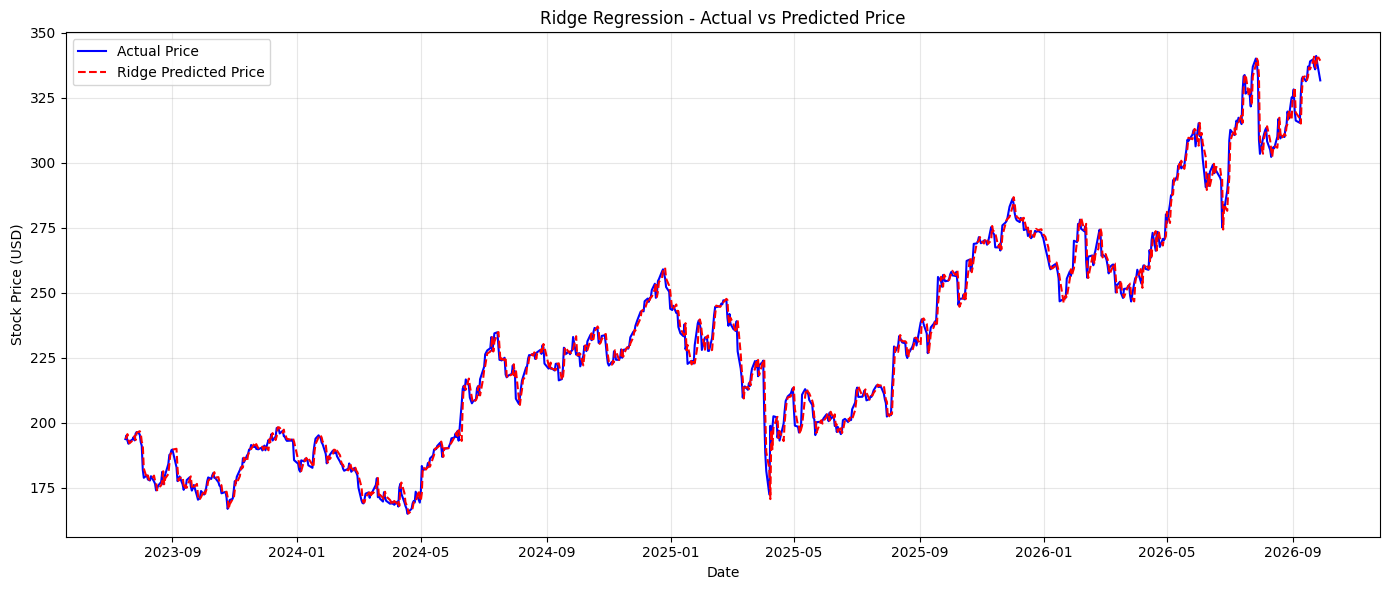

In [11]:
# ------------------------------------------------------------
# BIỂU ĐỒ 1: GIÁ THỰC TẾ VÀ GIÁ DỰ BÁO TRÊN TEST
# ------------------------------------------------------------

plt.figure(figsize=(14, 6))

plt.plot(
    dates_test, actual_test,
    label="Actual Price",
    color="blue",
    linewidth=1.5
)

plt.plot(
    dates_test, pred_test,
    label="Ridge Predicted Price",
    color="red",
    linestyle="--",
    linewidth=1.5
)

plt.title("Ridge Regression - Actual vs Predicted Price")
plt.xlabel("Date")
plt.ylabel("Stock Price (USD)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "Ridge_Charts/01_Actual_vs_Predicted.png",
    dpi=300
)
plt.show()

### Biểu đồ 2: So sánh chi tiết trong 100 phiên giao dịch cuối cùng của tập Test

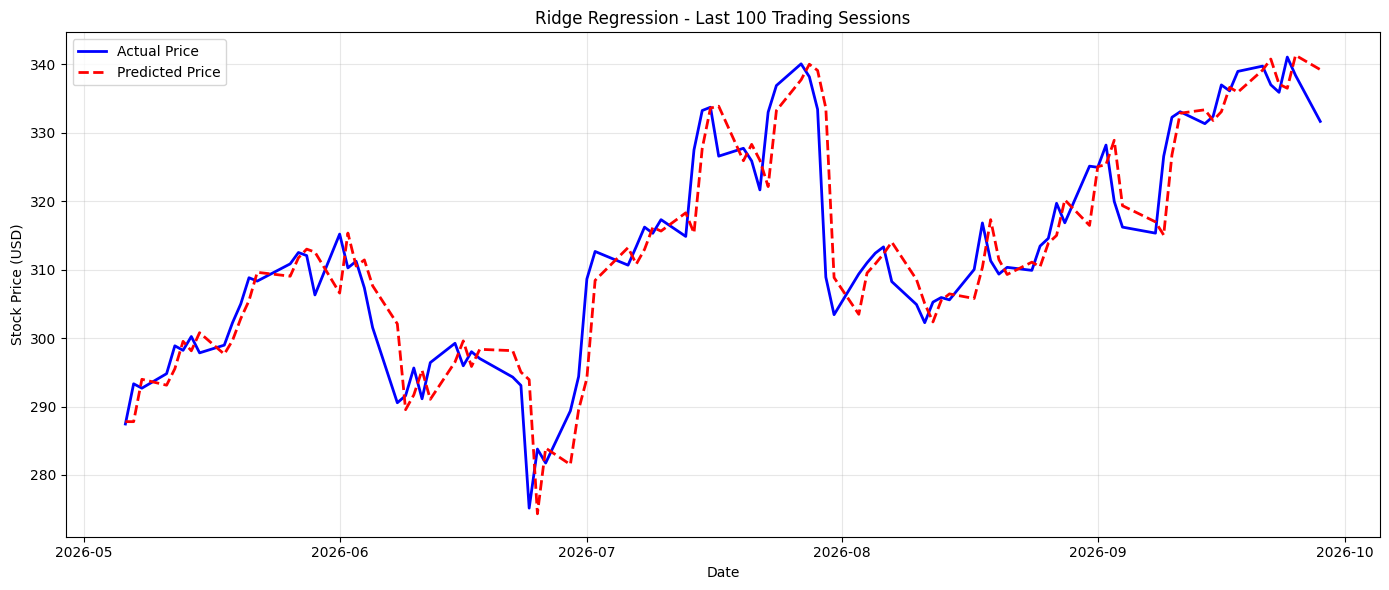

In [12]:
# ------------------------------------------------------------
# BIỂU ĐỒ 2: SO SÁNH 100 PHIÊN CUỐI CỦA TEST
# ------------------------------------------------------------

last_n = min(100, len(test))

plt.figure(figsize=(14, 6))

plt.plot(
    dates_test[-last_n:],
    actual_test[-last_n:],
    label="Actual Price",
    color="blue",
    linewidth=2
)

plt.plot(
    dates_test[-last_n:],
    pred_test[-last_n:],
    label="Predicted Price",
    color="red",
    linestyle="--",
    linewidth=2
)

plt.title("Ridge Regression - Last 100 Trading Sessions")
plt.xlabel("Date")
plt.ylabel("Stock Price (USD)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "Ridge_Charts/02_Last_100_Sessions.png",
    dpi=300
)
plt.show()

### Biểu đồ 3: Scatter Plot - Tương quan giữa Giá thực tế và Giá dự báo

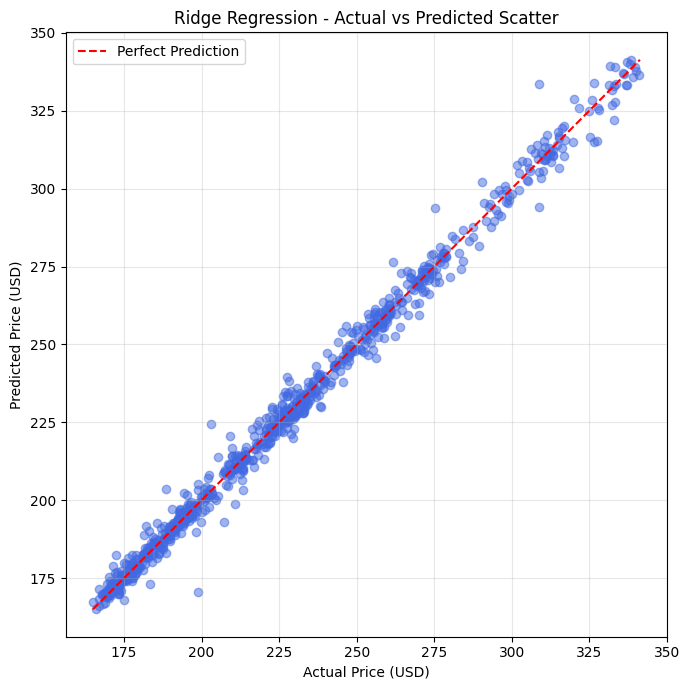

In [13]:
# ------------------------------------------------------------
# BIỂU ĐỒ 3: SCATTER ACTUAL VS PREDICTED
# ------------------------------------------------------------

plt.figure(figsize=(7, 7))

plt.scatter(
    actual_test,
    pred_test,
    alpha=0.5,
    color="royalblue"
)

min_price = min(actual_test.min(), pred_test.min())
max_price = max(actual_test.max(), pred_test.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    "r--",
    label="Perfect Prediction"
)

plt.title("Ridge Regression - Actual vs Predicted Scatter")
plt.xlabel("Actual Price (USD)")
plt.ylabel("Predicted Price (USD)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "Ridge_Charts/03_Scatter_Actual_Predicted.png",
    dpi=300
)
plt.show()

### Biểu đồ 4: Sai số dự báo (Residuals) theo thời gian

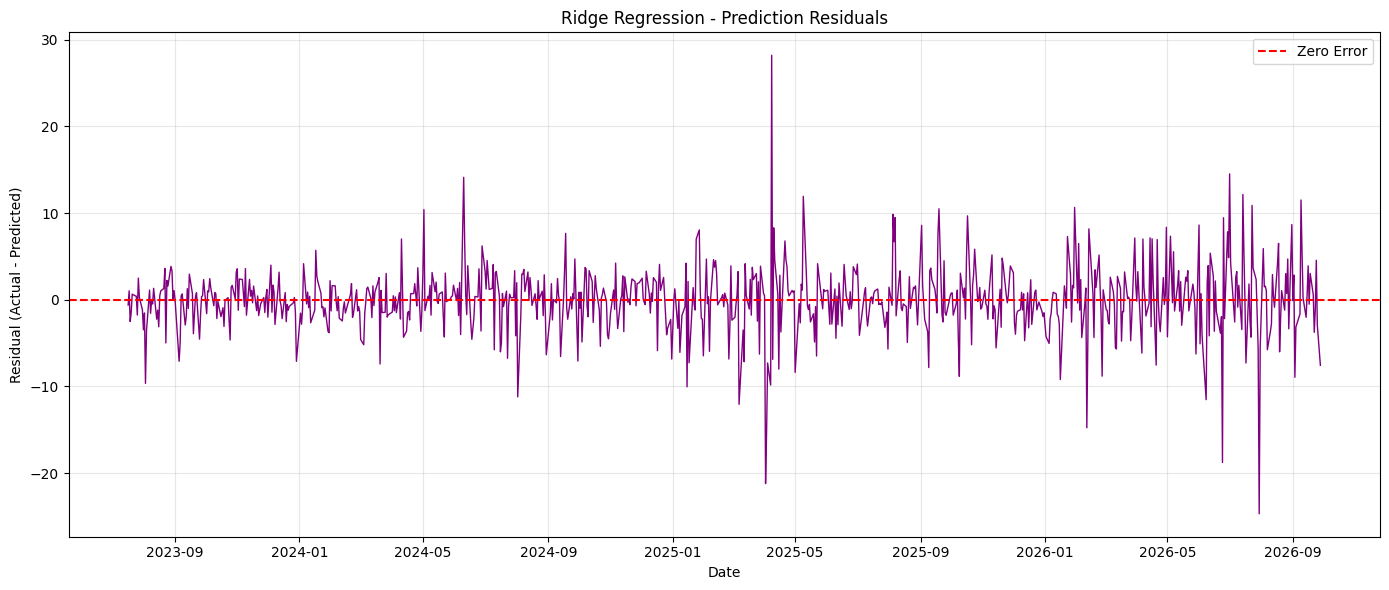

In [14]:
# ------------------------------------------------------------
# BIỂU ĐỒ 4: SAI SỐ DỰ BÁO THEO THỜI GIAN
# ------------------------------------------------------------

plt.figure(figsize=(14, 6))

plt.plot(
    dates_test,
    residuals,
    color="purple",
    linewidth=1
)

plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    label="Zero Error"
)

plt.title("Ridge Regression - Prediction Residuals")
plt.xlabel("Date")
plt.ylabel("Residual (Actual - Predicted)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "Ridge_Charts/04_Residuals_Over_Time.png",
    dpi=300
)
plt.show()

### Biểu đồ 5: Mức độ ảnh hưởng của 8 Feature (Standardized Coefficients)

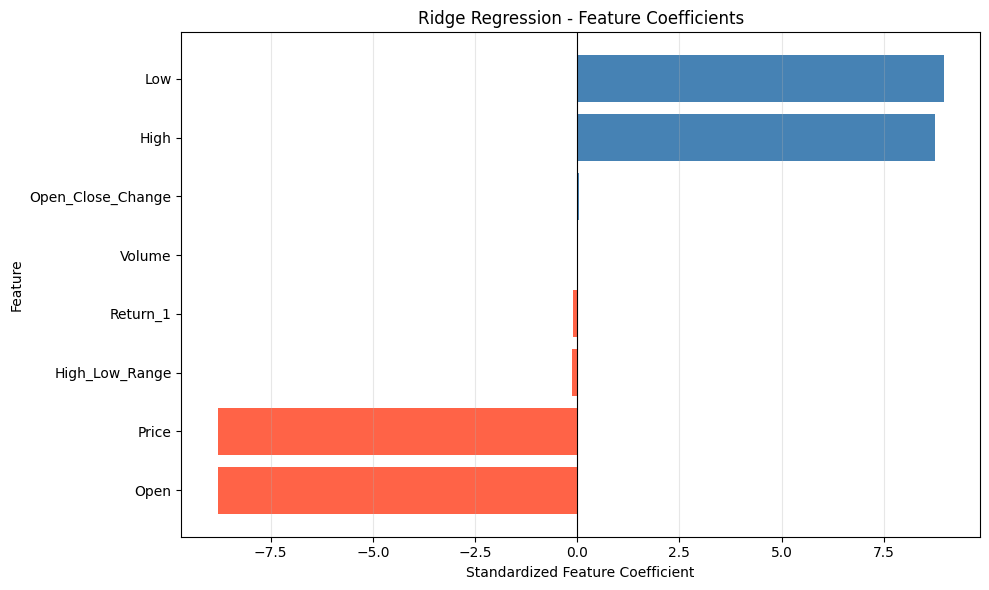

In [15]:
# ------------------------------------------------------------
# BIỂU ĐỒ 5: MỨC ĐỘ ẢNH HƯỞNG CỦA 8 FEATURE
# ------------------------------------------------------------

best_pipeline = ridge_model.best_estimator_
coefficients = best_pipeline.named_steps["ridge"].coef_

coef_df = pd.DataFrame({
    "Feature": feature_cols,
    "Coefficient": coefficients
}).sort_values("Coefficient")

plt.figure(figsize=(10, 6))

colors = [
    "tomato" if x < 0 else "steelblue"
    for x in coef_df["Coefficient"]
]

plt.barh(
    coef_df["Feature"],
    coef_df["Coefficient"],
    color=colors
)

plt.axvline(
    x=0,
    color="black",
    linewidth=0.8
)

plt.title("Ridge Regression - Feature Coefficients")
plt.xlabel("Standardized Feature Coefficient")
plt.ylabel("Feature")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "Ridge_Charts/05_Feature_Coefficients.png",
    dpi=300
)
plt.show()